In [ ]:
import os
import pickle
import soundfile as sf
import numpy as np

# Folder containing .pkl files
input_folder = r"E:\Input_images\Audio"
output_folder = r"E:\Input_images\Audio\converted_wav"
os.makedirs(output_folder, exist_ok=True)


# Set sample rate (change if needed)
samplerate = 16000

# Loop through all .pkl files
for filename in os.listdir(input_folder):
    if filename.endswith(".pkl"):
        pkl_path = os.path.join(input_folder, filename)

        # Load the pickle file
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)

        # Extract waveform (first row of data[0])
        waveform = data[0][0]  # Change indexing if needed

        # Convert to float32
        waveform = np.array(waveform, dtype='float32')

        # Create output .wav path
        base_name = os.path.splitext(filename)[0]
        wav_path = os.path.join(output_folder, base_name + ".wav")

        # Save as .wav
        sf.write(wav_path, waveform, samplerate)
        print("✅ Saved:", wav_path)

print("🎉 All files converted!")


✅ Saved: E:\Input_images\Audio\converted_wav\subject_01_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_02_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_03_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_04_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_05_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_06_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_07_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_08_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_09_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_10_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_11_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_12_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_13_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_14_aud.wav
✅ Saved: E:\Input_images\Audio\converted_wav\subject_15_aud.wav
✅ Saved: E:\Input_images\Audio\converted

In [ ]:
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from glob import glob
import noisereduce as nr
import IPython

In [ ]:
import os

folder_path = r"E:\Input_images\Audio"  

wav_files = [f for f in os.listdir(folder_path) if f.endswith('.wav')]
print(f"🎧 Total files found: {len(wav_files)}\n")

for f in wav_files:
    print(f)


🎧 Total files found: 1

converted.wav


In [ ]:
import soundfile as sf

# Local file path
file_path = r"E:\Input_images\Audio\converted.wav\subject_01_aud.wav"

# Read audio file
data, rate = sf.read(file_path)

print(f"Sample rate: {rate}")
print(f"Data shape: {data.shape}")

Sample rate: 16000
Data shape: (80000,)


In [ ]:
import IPython
IPython.display.Audio(data=data, rate=rate)

In [ ]:
import librosa
audio = r"E:\Input_images\Audio\converted.wav\subject_01_aud.wav"
y, sr = librosa.load(audio)

print(y.shape)

(110250,)


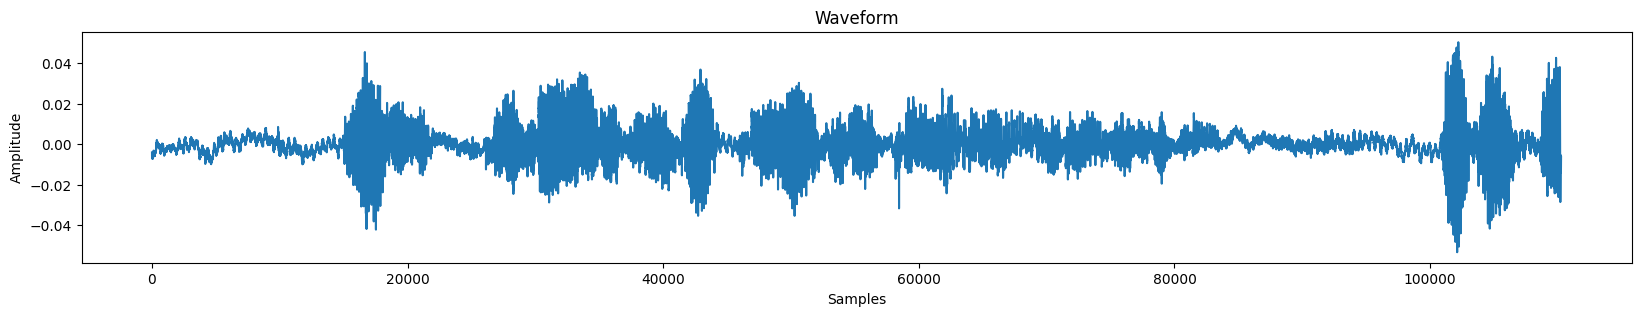

In [ ]:
fig, ax = plt.subplots(figsize=(20, 3))
ax.plot(y)
ax.set_title("Waveform")
ax.set_xlabel("Samples")
ax.set_ylabel("Amplitude")
plt.show()

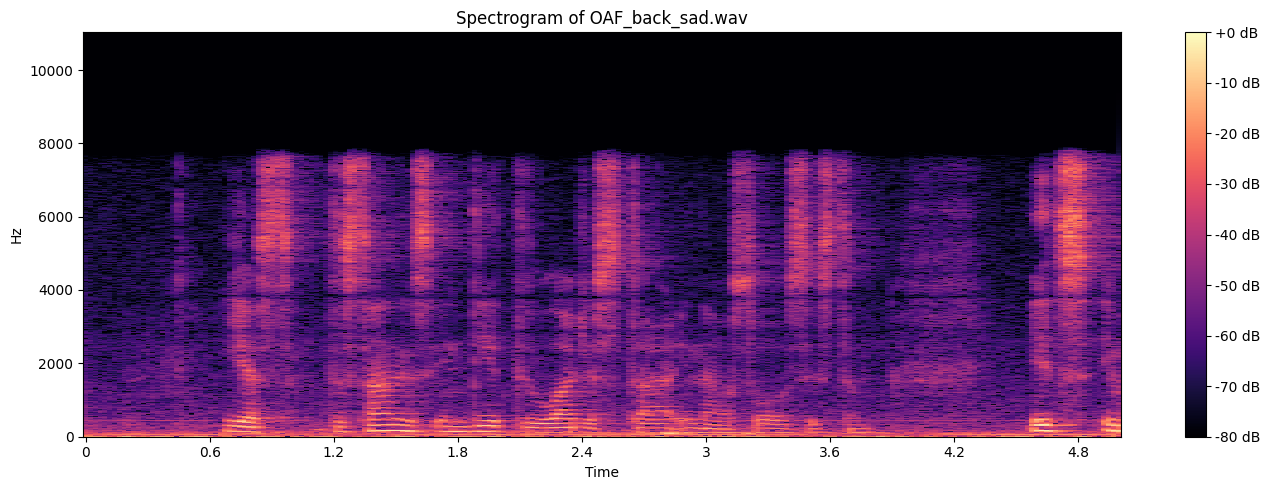

In [ ]:
# Compute STFT and convert to dB
D = np.abs(librosa.stft(y))
DB = librosa.amplitude_to_db(D, ref=np.max)

# Plot the spectrogram
plt.figure(figsize=(14, 5))
librosa.display.specshow(DB, sr=sr, x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram of OAF_back_sad.wav")
plt.tight_layout()
plt.show()

# readuce background noice

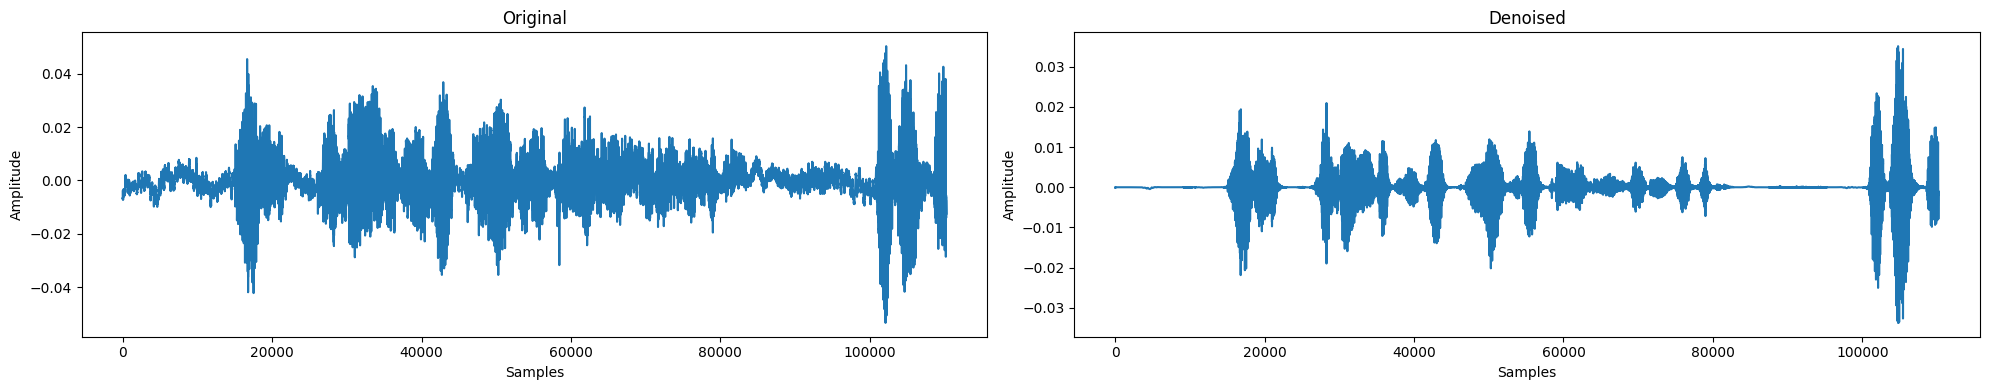

In [ ]:
import matplotlib.pyplot as plt
# Load audio
newfile_path = r"E:\Input_images\Audio\converted.wav\subject_01_aud.wav"
y, sr = librosa.load(newfile_path)

# Apply noise reduction
reduced_noise = nr.reduce_noise(y=y, sr=sr, stationary=True, n_std_thresh_stationary=1.5)

# Plot original vs denoised signal
plt.figure(figsize=(20, 4))

plt.subplot(1, 2, 1)
plt.title("Original")
plt.plot(y)
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.subplot(1, 2, 2)
plt.title("Denoised")
plt.plot(reduced_noise)
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

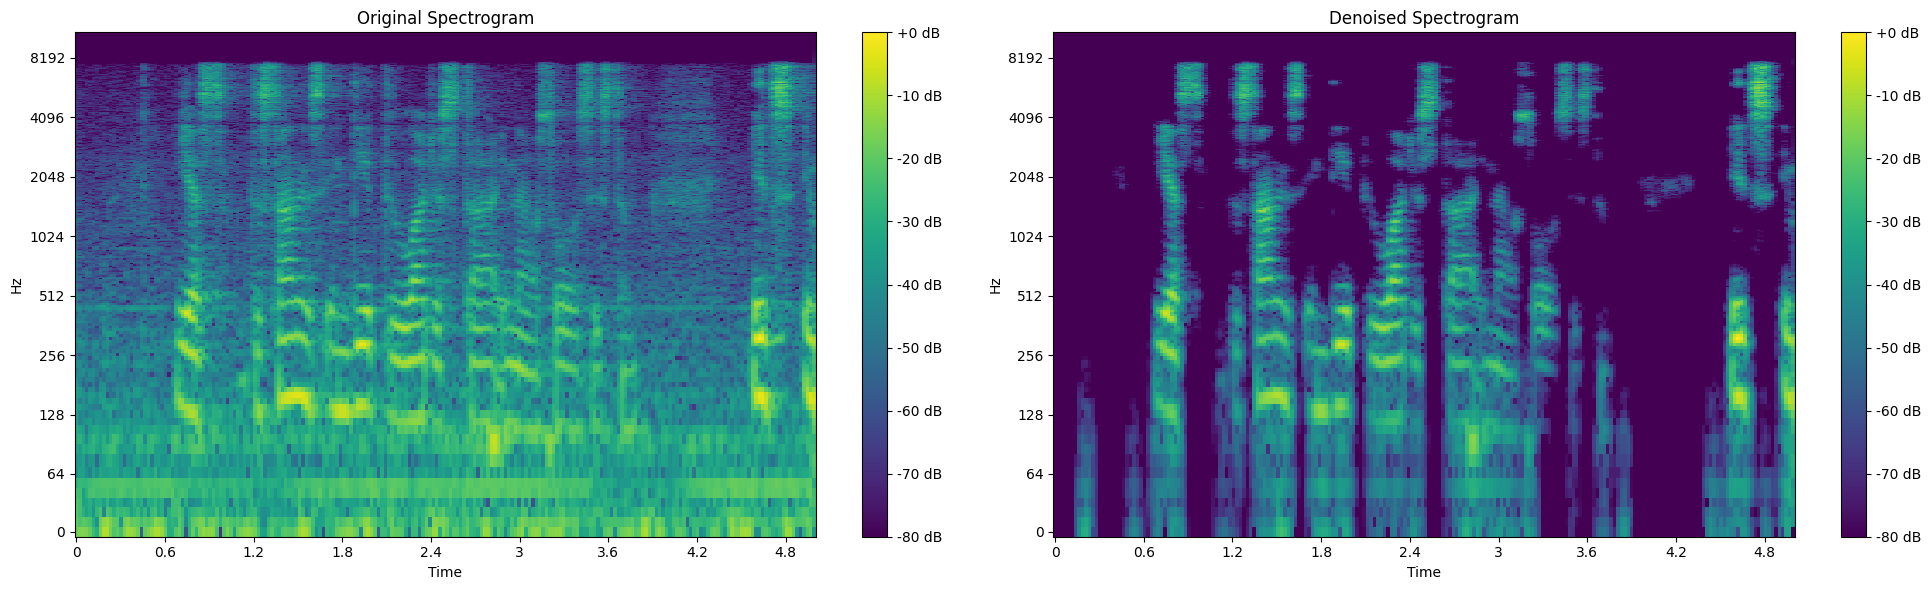

In [ ]:
D_orig = librosa.amplitude_to_db(abs(librosa.stft(y)), ref=np.max)
D_denoised = librosa.amplitude_to_db(abs(librosa.stft(reduced_noise)), ref=np.max)

# Plot Spectrograms
plt.figure(figsize=(20, 6))

plt.subplot(1, 2, 1)
librosa.display.specshow(D_orig, sr=sr, x_axis='time', y_axis='log', cmap='viridis')
plt.title('Original Spectrogram')
plt.colorbar(format='%+2.0f dB')

plt.subplot(1, 2, 2)
librosa.display.specshow(D_denoised, sr=sr, x_axis='time', y_axis='log', cmap='viridis')
plt.title('Denoised Spectrogram')
plt.colorbar(format='%+2.0f dB')

plt.tight_layout()
plt.show()


In [ ]:
import soundfile as sf

# Save denoised audio to a file
sf.write("denoised_audio.wav", reduced_noise, sr)

In [ ]:
from IPython.display import Audio, display

denoised_path = r"E:\PYTHON\program\venv2\denoised_audio.wav"
display(Audio(denoised_path))

# trim audio

In [ ]:
import librosa

# Load the audio
file_path = r"E:\PYTHON\program\venv2\denoised_audio.wav"
y, sr = librosa.load(file_path)

# Trim leading and trailing silence
trimmed_audio, index = librosa.effects.trim(y, top_db=20)

print(f"Trimmed from sample {index[0]} to {index[1]}")
sf.write("E:/PYTHON/program/venv2/trimmed_audio.wav", trimmed_audio, sr)

Trimmed from sample 14848 to 110250


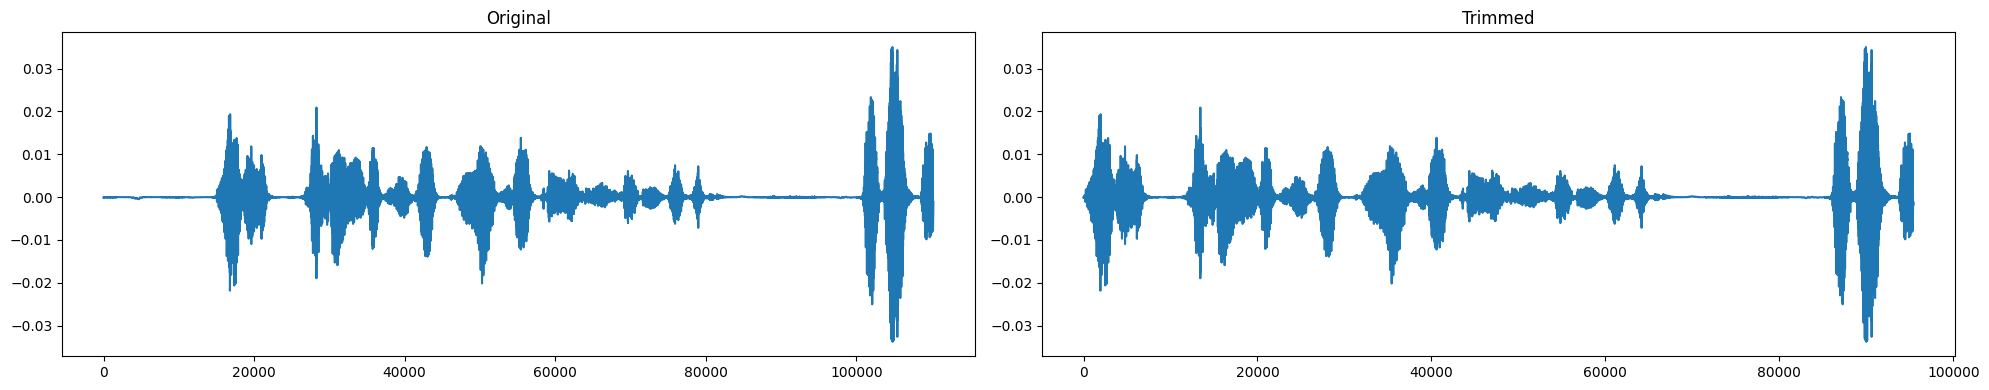

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 4))
plt.subplot(1, 2, 1)
plt.title("Original")
plt.plot(y)
plt.subplot(1, 2, 2)
plt.title("Trimmed")
plt.plot(trimmed_audio)
plt.tight_layout()
plt.show()


# save the trimed audio

In [ ]:
trimmed_path =r"E:\PYTHON\program\venv2\trimmed_audio.wav"
sf.write(trimmed_path, trimmed_audio, sr)


y, sb = librosa.load(trimmed_path)
print(f"Reloaded trimmed audio shape: {y.shape}")

Reloaded trimmed audio shape: (95402,)


In [ ]:
from IPython.display import Audio, display

trimmed_path = r"E:\PYTHON\program\venv2\trimmed_audio.wav"
display(Audio(trimmed_path))


In [ ]:
import os
import librosa
import noisereduce as nr
import soundfile as sf

# Input and output root folders
input_root = r"E:\Input_images\Audio\converted.wav"
output_root = r"E:\voic_clean"
os.makedirs(output_root, exist_ok=True)

# Loop through all subfolders and .wav files
for root, dirs, files in os.walk(input_root):
    for file_name in files:
        if file_name.endswith(".wav"):
            try:
                full_input = os.path.join(root, file_name)

                # Recreate relative path inside output folder
                rel_path = os.path.relpath(full_input, input_root)
                full_output = os.path.join(output_root, rel_path)
                os.makedirs(os.path.dirname(full_output), exist_ok=True)

                # Load
                y, sr = librosa.load(full_input, sr=16000, mono=True)

                # Trim
                y_trimmed, _ = librosa.effects.trim(y, top_db=20)

                # Denoise
                y_denoised = nr.reduce_noise(y=y_trimmed, sr=sr, stationary=True)

                # Normalize
                if max(abs(y_denoised)) > 0:
                    y_normalized = y_denoised / max(abs(y_denoised))
                else:
                    y_normalized = y_denoised

                # Save cleaned audio
                sf.write(full_output, y_normalized, sr)
                print(f"✅ Saved: {rel_path}")

            except Exception as e:
                print(f"❌ Error processing {file_name}: {e}")


✅ Saved: subject_01_aud.wav
✅ Saved: subject_02_aud.wav
✅ Saved: subject_03_aud.wav
✅ Saved: subject_04_aud.wav
✅ Saved: subject_05_aud.wav
✅ Saved: subject_06_aud.wav
✅ Saved: subject_07_aud.wav
✅ Saved: subject_08_aud.wav
✅ Saved: subject_09_aud.wav
✅ Saved: subject_10_aud.wav
✅ Saved: subject_11_aud.wav
✅ Saved: subject_12_aud.wav
✅ Saved: subject_13_aud.wav
✅ Saved: subject_14_aud.wav
✅ Saved: subject_15_aud.wav
✅ Saved: subject_16_aud.wav
✅ Saved: subject_17_aud.wav
✅ Saved: subject_18_aud.wav
✅ Saved: subject_19_aud.wav
✅ Saved: subject_20_aud.wav
✅ Saved: subject_21_aud.wav
✅ Saved: subject_22_aud.wav
✅ Saved: subject_23_aud.wav
✅ Saved: subject_24_aud.wav
✅ Saved: subject_25_aud.wav
✅ Saved: subject_26_aud.wav
✅ Saved: subject_27_aud.wav
✅ Saved: subject_28_aud.wav
✅ Saved: subject_29_aud.wav
✅ Saved: subject_30_aud.wav
✅ Saved: subject_31_aud.wav
✅ Saved: subject_32_aud.wav
✅ Saved: subject_33_aud.wav
✅ Saved: subject_34_aud.wav
✅ Saved: subject_35_aud.wav
✅ Saved: subject_36_

In [ ]:
def extract_audio_features(file_path, sr=16000):
    try:
        y, sr = librosa.load(file_path, sr=sr, mono=True)
        features = {}

        # MFCC
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        for i in range(13):
            features[f'mfcc_{i}_mean'] = np.mean(mfccs[i])
            features[f'mfcc_{i}_std'] = np.std(mfccs[i])

        # Spectral Features
        features['spec_centroid_mean'] = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
        features['spec_rolloff_mean'] = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
        features['spec_bw_mean'] = np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr))

        # ZCR
        features['zcr_mean'] = np.mean(librosa.feature.zero_crossing_rate(y))

        # Chroma
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        for i in range(12):
            features[f'chroma_{i}_mean'] = np.mean(chroma[i])

        # Pitch
        pitches, mags = librosa.piptrack(y=y, sr=sr)
        pitches = pitches[mags > np.median(mags)]
        pitches = pitches[pitches > 0]
        features['pitch_mean'] = np.mean(pitches) if len(pitches) > 0 else 0
        features['pitch_std'] = np.std(pitches) if len(pitches) > 0 else 0

        # RMS Energy
        rms = librosa.feature.rms(y=y)[0]
        features['rms_mean'] = np.mean(rms)
        features['rms_std'] = np.std(rms)

        # Duration & Tempo
        features['duration'] = librosa.get_duration(y=y, sr=sr)
        features['tempo'] = librosa.beat.tempo(y=y, sr=sr)[0]

        return features
    except Exception as e:
        print(f"❌ Error processing {file_path}: {e}")
        return None



In [ ]:
def extract_features_from_folder(folder_path):
    all_features = []
    file_names = []

    for file in os.listdir(folder_path):
        if file.endswith(".wav"):
            file_path = os.path.join(folder_path, file)
            features = extract_audio_features(file_path)

            if features:
                features['file_name'] = file
                all_features.append(features)
                print(f"✅ Done: {file}")
            else:
                print(f"⚠️ Skipped: {file}")

    df = pd.DataFrame(all_features)
    return df


In [ ]:
import pandas as pd
voice_clean_path = r"E:\cleaned dataset\voic_clean"
features_df = extract_features_from_folder(voice_clean_path)

# Save to CSV
csv_output_path = os.path.join(voice_clean_path, "voice_features.csv")
features_df.to_csv(csv_output_path, index=False)

print(f"\n✅ Feature CSV saved to: {csv_output_path}")


C:\Users\Rahul\AppData\Local\Temp\ipykernel_20224\746551496.py:39: FutureWarning: librosa.beat.tempo
	This function was moved to 'librosa.feature.rhythm.tempo' in librosa version 0.10.0.
	This alias will be removed in librosa version 1.0.
  features['tempo'] = librosa.beat.tempo(y=y, sr=sr)[0]


✅ Done: subject_01_aud.wav
✅ Done: subject_02_aud.wav
✅ Done: subject_03_aud.wav
✅ Done: subject_04_aud.wav
✅ Done: subject_05_aud.wav
✅ Done: subject_06_aud.wav
✅ Done: subject_07_aud.wav
✅ Done: subject_08_aud.wav
✅ Done: subject_09_aud.wav
✅ Done: subject_10_aud.wav
✅ Done: subject_11_aud.wav
✅ Done: subject_12_aud.wav
✅ Done: subject_13_aud.wav
✅ Done: subject_14_aud.wav
✅ Done: subject_15_aud.wav
✅ Done: subject_16_aud.wav
✅ Done: subject_17_aud.wav
✅ Done: subject_18_aud.wav
✅ Done: subject_19_aud.wav
✅ Done: subject_20_aud.wav
✅ Done: subject_21_aud.wav
✅ Done: subject_22_aud.wav
✅ Done: subject_23_aud.wav
✅ Done: subject_24_aud.wav
✅ Done: subject_25_aud.wav
✅ Done: subject_26_aud.wav
✅ Done: subject_27_aud.wav
✅ Done: subject_28_aud.wav
✅ Done: subject_29_aud.wav
✅ Done: subject_30_aud.wav
✅ Done: subject_31_aud.wav
✅ Done: subject_32_aud.wav
✅ Done: subject_33_aud.wav
✅ Done: subject_34_aud.wav
✅ Done: subject_35_aud.wav
✅ Done: subject_36_aud.wav
✅ Done: subject_37_aud.wav


e:\PYTHON\program\venv2\venv310\lib\site-packages\librosa\core\pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(


✅ Done: subject_38_aud.wav
✅ Done: subject_39_aud.wav
✅ Done: subject_40_aud.wav
✅ Done: subject_41_aud.wav
✅ Done: subject_42_aud.wav

✅ Feature CSV saved to: E:\cleaned dataset\voic_clean\voice_features.csv


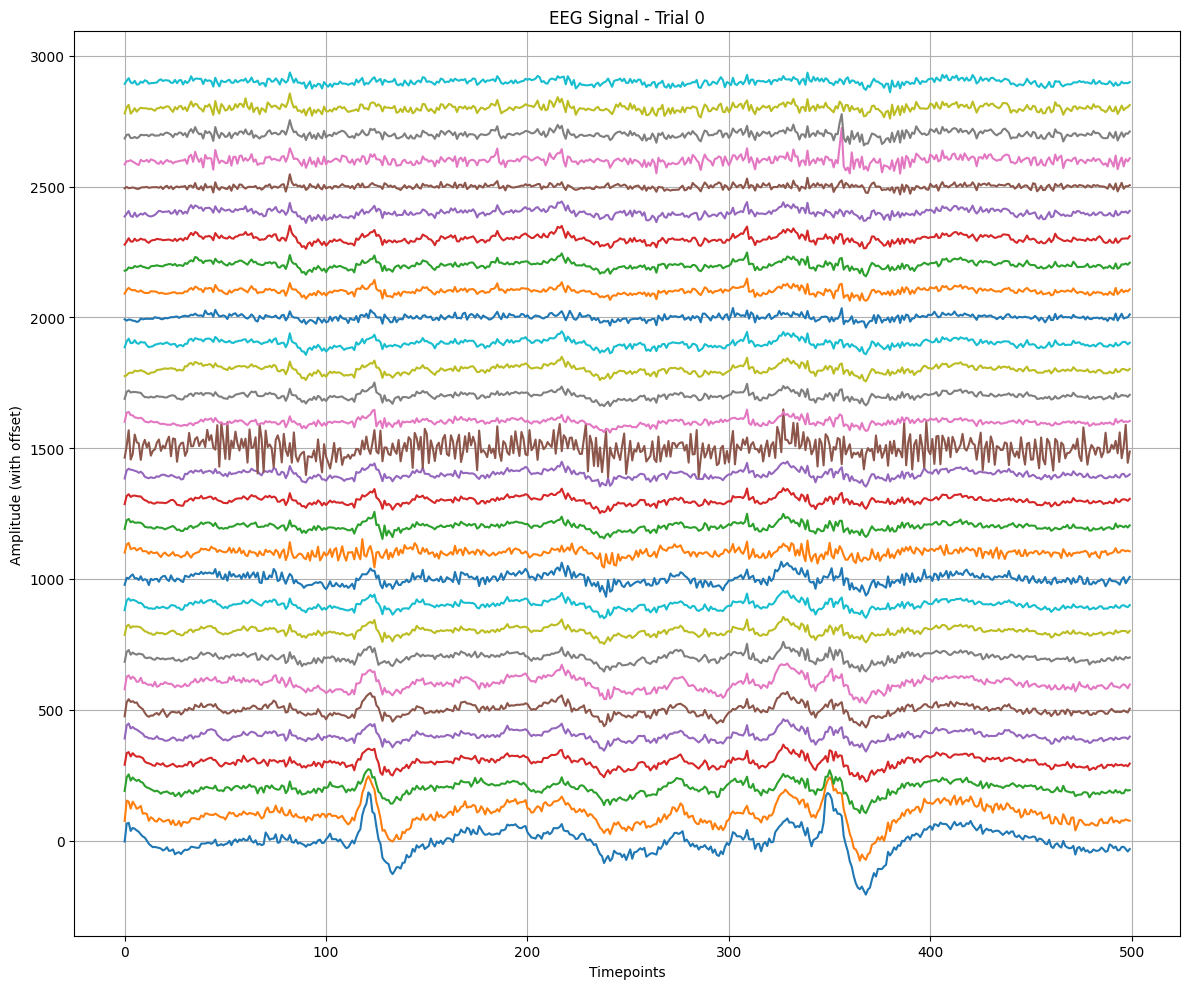

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load the .pkl EEG file
file_path = r"E:\Input_images\EEG\subject_01_eeg.pkl"

with open(file_path, 'rb') as f:
    data = pickle.load(f)

# Step 2: Extract EEG data from list (based on earlier structure)
eeg_data = data[0]  # Shape: (280, 30, 500) -> 280 trials, 30 channels, 500 samples
labels = data[1]    # Optional: Labels for each trial

# Step 3: Select trial and plot
trial_index = 0  # You can change to any 0 - 279
trial = eeg_data[trial_index]  # Shape: (30, 500)

# Plot all 30 EEG channels
plt.figure(figsize=(12, 10))
for i in range(trial.shape[0]):
    plt.plot(trial[i] + i * 100, label=f'Channel {i}')  # Offset vertically

plt.title(f"EEG Signal - Trial {trial_index}")
plt.xlabel("Timepoints")
plt.ylabel("Amplitude (with offset)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
eeg_data = data[0]
print(eeg_data.shape)


(280, 30, 500)


EEG shape: (280, 30, 500)


C:\Users\Rahul\AppData\Local\Temp\ipykernel_20224\1123348286.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab20', 30)  # 30 distinct colors


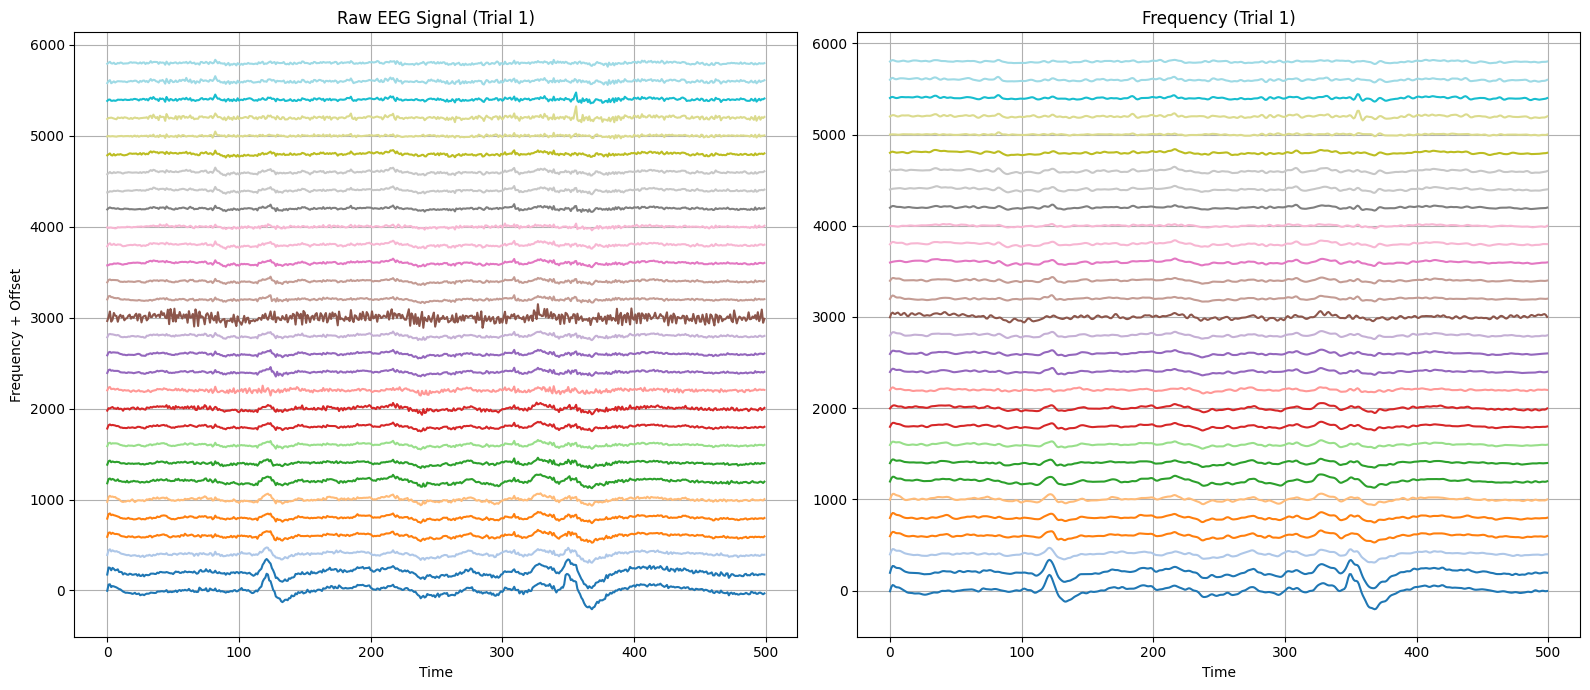

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# ------------------------------
# 1. Load EEG .pkl file
# ------------------------------
file_path = r"E:\Input_images\EEG\subject_01_eeg.pkl"

with open(file_path, 'rb') as f:
    data = pickle.load(f)

# ------------------------------
# 2. Extract EEG data
# ------------------------------
eeg_raw = data[0]  # Shape: (280, 30, 500)
print("EEG shape:", eeg_raw.shape)  # 280 trials, 30 channels, 500 samples

# ------------------------------
# 3. Select one trial
# ------------------------------
trial = eeg_raw[0]  # (30, 500)

# ------------------------------
# 4. Bandpass Filter (1-50 Hz)
# ------------------------------
def bandpass_filter(data, lowcut=1.0, highcut=50.0, fs=250.0, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

filtered_trial = np.array([bandpass_filter(ch) for ch in trial])

# ------------------------------
# 5. Baseline Correction
# ------------------------------
cleaned_trial = filtered_trial - np.mean(filtered_trial, axis=1, keepdims=True)

# ------------------------------
# 6. Plotting with colors
# ------------------------------
colors = plt.cm.get_cmap('tab20', 30)  # 30 distinct colors

plt.figure(figsize=(16, 7))

# Before Cleaning
plt.subplot(1, 2, 1)
for i in range(30):
    plt.plot(trial[i] + i * 200, color=colors(i), label=f"Ch {i+1}")
plt.title("Raw EEG Signal (Trial 1)")
plt.xlabel("Time")
plt.ylabel("Frequency + Offset")
plt.grid(True)

# After Cleaning
plt.subplot(1, 2, 2)
for i in range(30):
    plt.plot(cleaned_trial[i] + i * 200, color=colors(i), label=f"Ch {i+1}")
plt.title("Frequency (Trial 1)")
plt.xlabel("Time")
plt.grid(True)

plt.tight_layout()
plt.show()


C:\Users\Rahul\AppData\Local\Temp\ipykernel_20224\4186659246.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', 10)


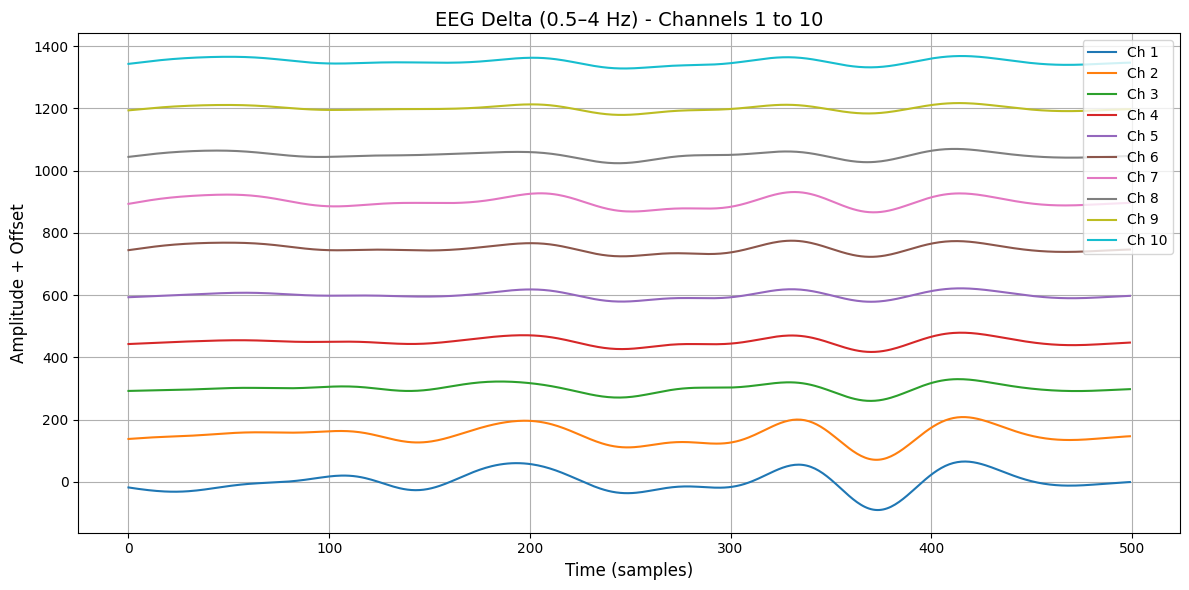

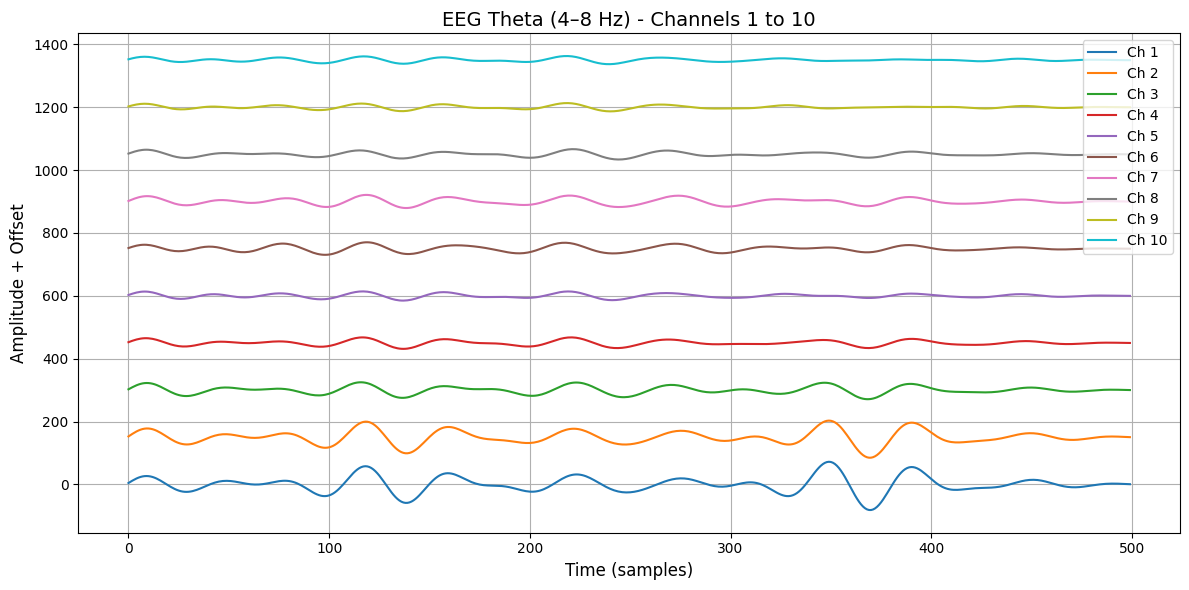

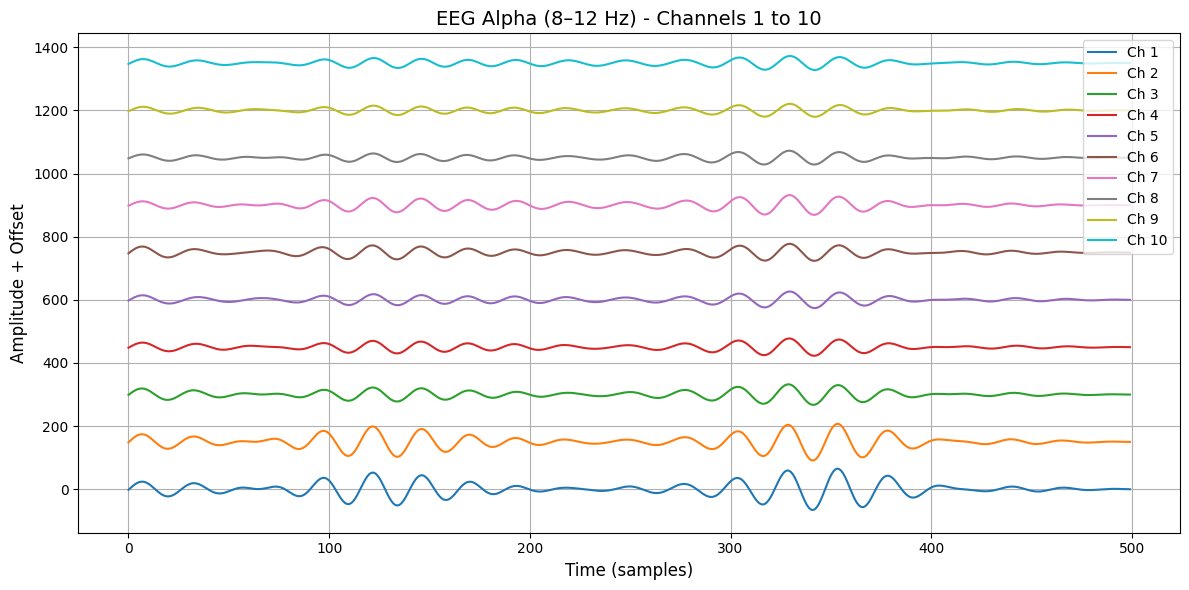

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# ------------------------------
# Load EEG data
# ------------------------------
file_path = r"E:\Input_images\EEG\subject_01_eeg.pkl"
with open(file_path, 'rb') as f:
    data = pickle.load(f)

eeg_raw = data[0]  # (280, 30, 500)
trial = eeg_raw[0]  # One trial: shape (30, 500)

# ------------------------------
# Bandpass Filter Function
# ------------------------------
def bandpass_filter(data, lowcut, highcut, fs=250.0, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# ------------------------------
# EEG Bands Definitions
# ------------------------------
bands = {
    "Delta (0.5–4 Hz)": (0.5, 4),
    "Theta (4–8 Hz)": (4, 8),
    "Alpha (8–12 Hz)": (8, 12)
}

# ------------------------------
# Plot each band for channels 1–10
# ------------------------------
for band_name, (low, high) in bands.items():
    filtered = np.array([bandpass_filter(ch, low, high) for ch in trial])
    cleaned = filtered - np.mean(filtered, axis=1, keepdims=True)

    plt.figure(figsize=(12, 6))
    colors = plt.cm.get_cmap('tab10', 10)

    for i in range(10):  # Channels 0–9 (i.e., Ch 1–10)
        plt.plot(cleaned[i] + i * 150, color=colors(i), label=f"Ch {i+1}")

    plt.title(f"EEG {band_name} - Channels 1 to 10", fontsize=14)
    plt.xlabel("Time (samples)", fontsize=12)
    plt.ylabel("Amplitude + Offset", fontsize=12)
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


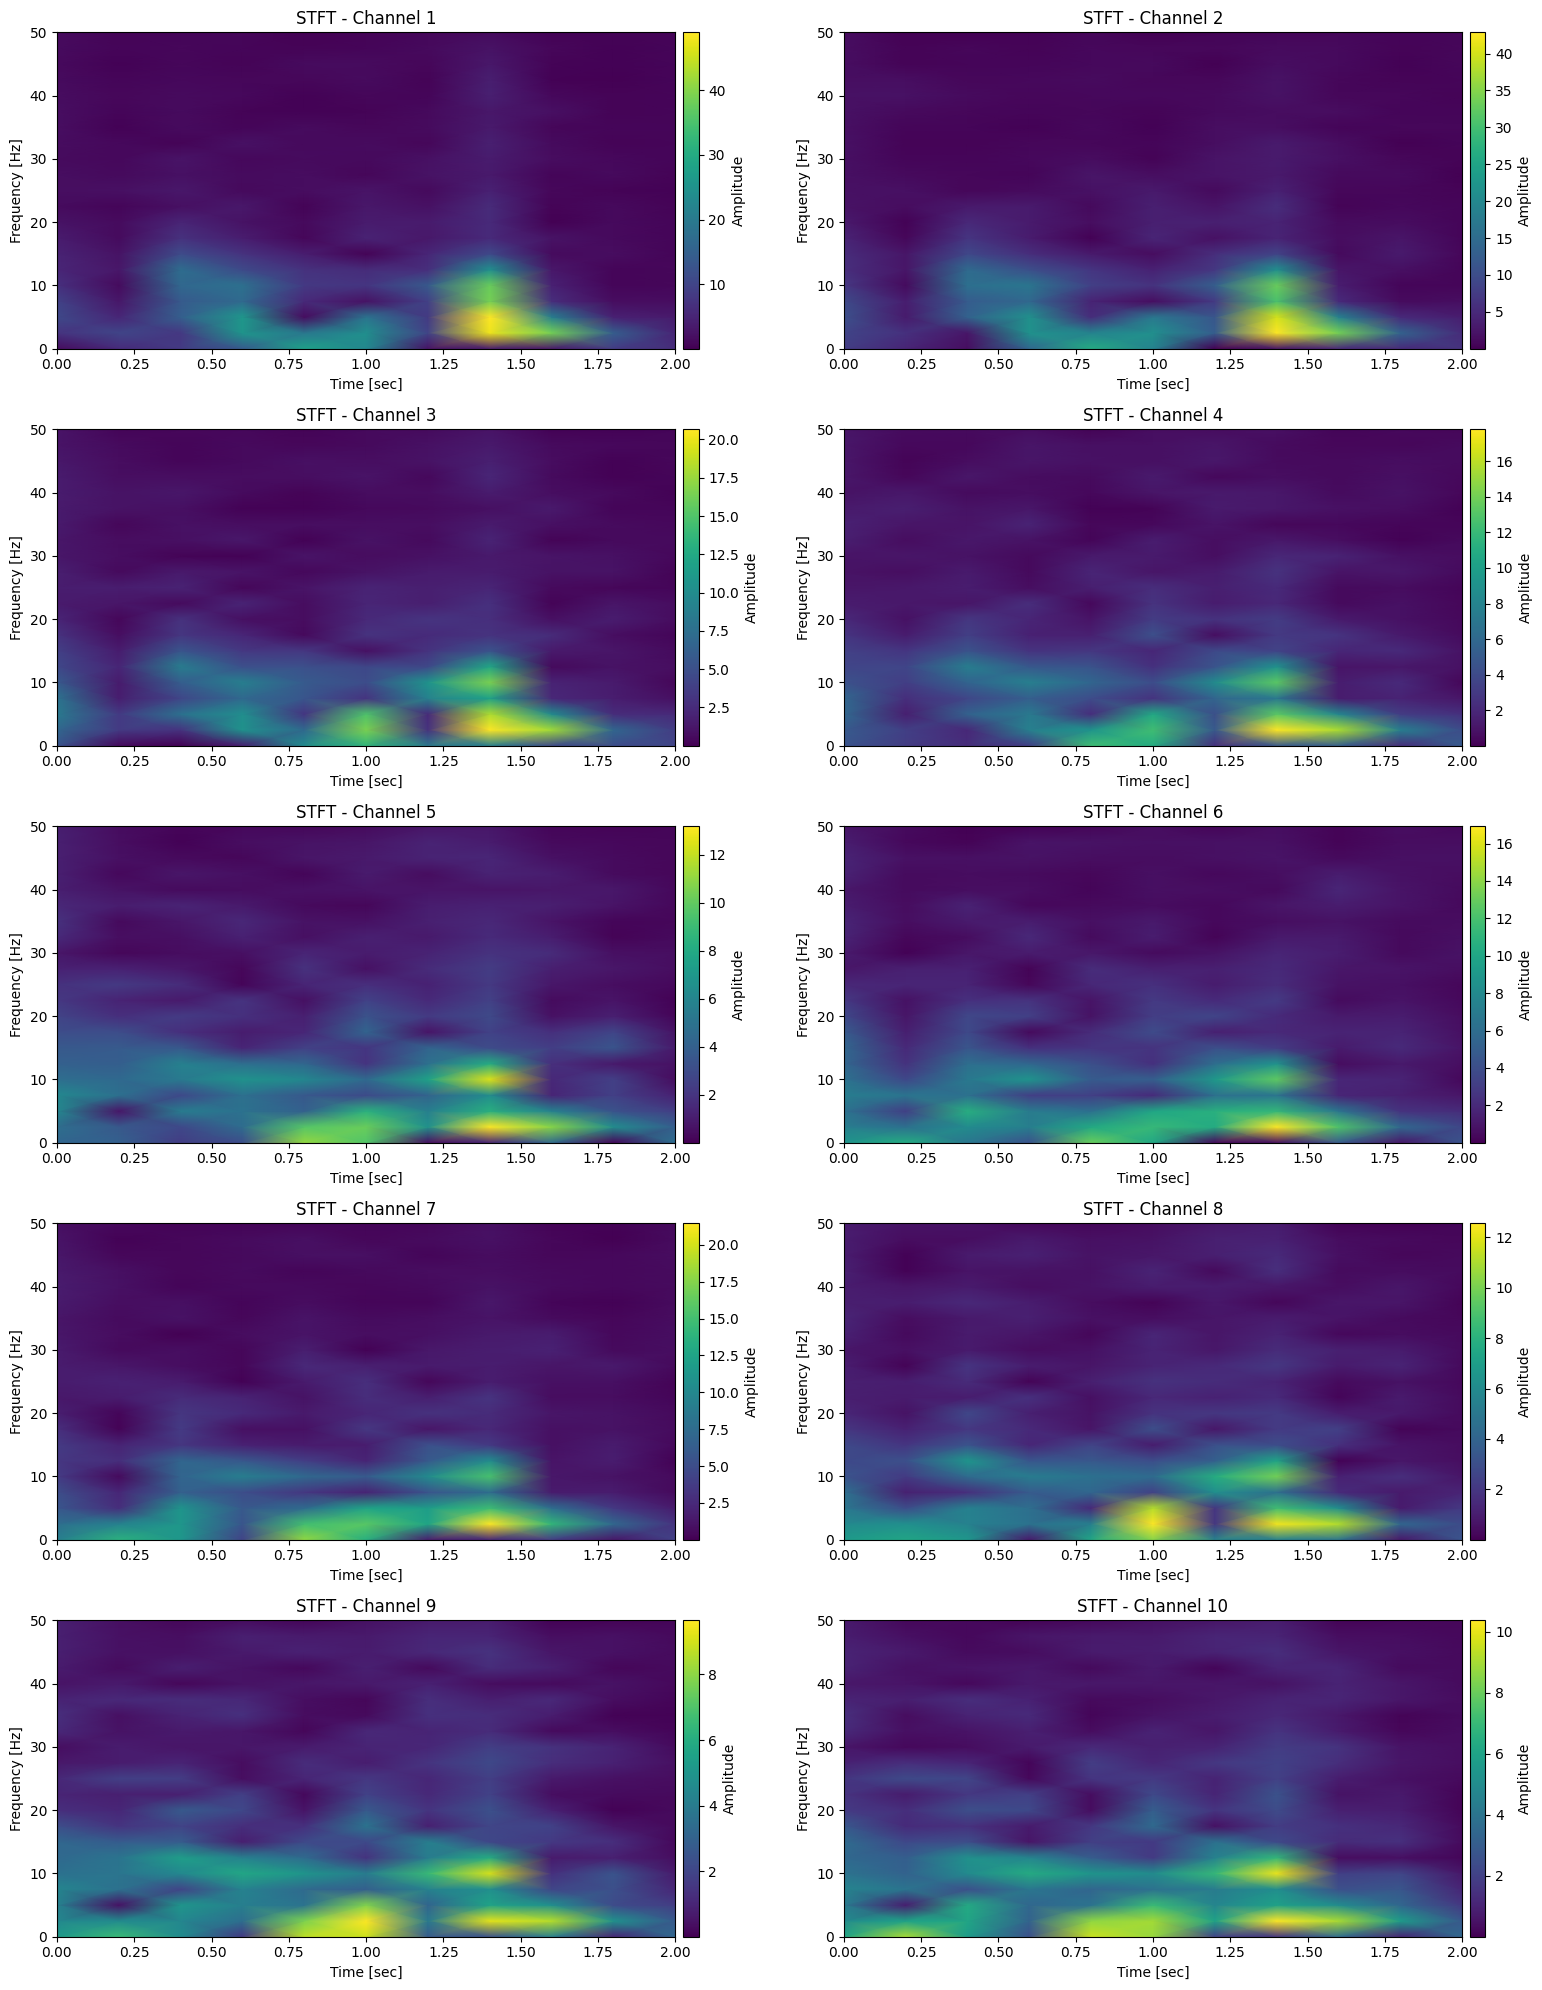

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, stft

# ----------------------------------------
# 1. Load EEG Data
# ----------------------------------------
file_path = r"E:\Input_images\EEG\subject_01_eeg.pkl"
with open(file_path, 'rb') as f:
    data = pickle.load(f)

eeg_raw = data[0]  # Shape: (280, 30, 500)
fs = 250  # Sampling frequency (Hz)

# ----------------------------------------
# 2. Bandpass Filter (1–50 Hz)
# ----------------------------------------
def bandpass_filter(signal, lowcut=1.0, highcut=50.0, fs=250.0, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal)

# ----------------------------------------
# 3. Select Trial and Filter
# ----------------------------------------
trial = eeg_raw[0]  # shape: (30, 500)
filtered_trial = np.array([bandpass_filter(ch, fs=fs) for ch in trial])

# ----------------------------------------
# 4. Plot STFT for Channels 1 to 10
# ----------------------------------------
plt.figure(figsize=(16, 20))
for i in range(10):  # Channels 0–9 (1 to 10)
    f, t, Zxx = stft(filtered_trial[i], fs=fs, nperseg=100)
    
    plt.subplot(5, 2, i+1)
    plt.pcolormesh(t, f, np.abs(Zxx), shading='gouraud')
    plt.title(f'STFT - Channel {i+1}')
    plt.ylabel('Frequency [Hz]')
    plt.xlabel('Time [sec]')
    plt.ylim(0, 50)  # Focus on 0–50 Hz EEG bands
    plt.colorbar(label='Amplitude', pad=0.01)

plt.tight_layout()
plt.show()


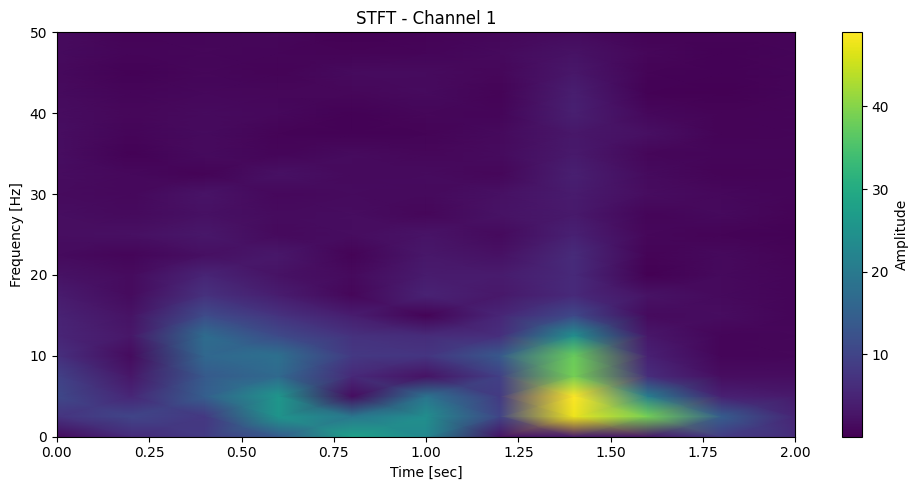

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, stft

# ----------------------------------------
# 1. Load EEG Data
# ----------------------------------------
file_path = r"E:\Input_images\EEG\subject_01_eeg.pkl"
with open(file_path, 'rb') as f:
    data = pickle.load(f)

eeg_raw = data[0]  # Shape: (280, 30, 500)
fs = 250  # Sampling frequency (Hz)

# ----------------------------------------
# 2. Bandpass Filter (1–50 Hz)
# ----------------------------------------
def bandpass_filter(signal, lowcut=1.0, highcut=50.0, fs=250.0, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal)

# ----------------------------------------
# 3. Select Trial and Filter Channel 1
# ----------------------------------------
trial = eeg_raw[0]       # shape: (30, 500)
channel_1 = trial[0]     # Channel 1 = index 0
filtered_ch1 = bandpass_filter(channel_1, fs=fs)

# ----------------------------------------
# 4. STFT Plot for Channel 1
# ----------------------------------------
f, t, Zxx = stft(filtered_ch1, fs=fs, nperseg=100)

plt.figure(figsize=(10, 5))
plt.pcolormesh(t, f, np.abs(Zxx), shading='gouraud')
plt.title("STFT - Channel 1")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [sec]")
plt.ylim(0, 50)  # Limit to EEG range
plt.colorbar(label="Amplitude")
plt.tight_layout()
plt.show()


In [ ]:
import os
import pickle
import numpy as np
from scipy.signal import butter, filtfilt
import matplotlib.pyplot as plt

# ------------------------------
# 1. Bandpass Filter Function
# ------------------------------
def bandpass_filter(data, lowcut=1.0, highcut=50.0, fs=250.0, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# ------------------------------
# 2. Folder Paths
# ------------------------------
input_folder = r"E:\Input_images\EEG"
output_folder = r"E:\Cleaned_EEG"

os.makedirs(output_folder, exist_ok=True)

# ------------------------------
# 3. Process Each .pkl File
# ------------------------------
for filename in os.listdir(input_folder):
    if filename.endswith(".pkl"):
        file_path = os.path.join(input_folder, filename)
        print(f"🔄 Processing {filename}...")

        try:
            # Load file
            with open(file_path, 'rb') as f:
                data = pickle.load(f)

            # EEG data assumed at index 0
            eeg_data = data[0]  # shape: (trials, channels, samples)

            cleaned_data = []

            for trial in eeg_data:
                filtered = np.array([bandpass_filter(ch) for ch in trial])
                baseline_corrected = filtered - np.mean(filtered, axis=1, keepdims=True)
                cleaned_data.append(baseline_corrected)

            cleaned_data = np.array(cleaned_data)

            # Update and save
            data[0] = cleaned_data

            output_path = os.path.join(output_folder, filename)
            with open(output_path, 'wb') as f:
                pickle.dump(data, f)

            print(f"✅ Saved cleaned: {output_path}")

        except Exception as e:
            print(f"❌ Error processing {filename}: {e}")


🔄 Processing subject_01_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_01_eeg.pkl
🔄 Processing subject_02_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_02_eeg.pkl
🔄 Processing subject_03_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_03_eeg.pkl
🔄 Processing subject_04_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_04_eeg.pkl
🔄 Processing subject_05_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_05_eeg.pkl
🔄 Processing subject_06_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_06_eeg.pkl
🔄 Processing subject_07_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_07_eeg.pkl
🔄 Processing subject_08_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_08_eeg.pkl
🔄 Processing subject_09_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_09_eeg.pkl
🔄 Processing subject_10_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_10_eeg.pkl
🔄 Processing subject_11_eeg.pkl...
✅ Saved cleaned: E:\Cleaned_EEG\subject_11_eeg.pkl
🔄 Processing subject_12_eeg.pkl...
✅ Saved cleaned: E:

In [ ]:
import os
import numpy as np
import pandas as pd
import pickle
from scipy.signal import welch

# Band definitions
EEG_BANDS = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alpha': (8, 12),
    'beta': (12, 30),
    'gamma': (30, 100)
}

# Compute bandpower
def bandpower(data, sf, band, axis=-1):
    fmin, fmax = band
    freqs, psd = welch(data, sf, nperseg=1024)
    idx_band = np.logical_and(freqs >= fmin, freqs <= fmax)
    return np.mean(psd[..., idx_band], axis=-1)

# Extract EEG features
def extract_eeg_features_from_pkl(file_path, sf=250):
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    if isinstance(data, list):
        for d in data:
            if isinstance(d, np.ndarray) and d.ndim >= 2:
                data = d
                break

    # Shape: (channels, time) or (samples, channels, time)
    if data.ndim == 3:
        data = data[0]  # Take the first sample if shape = (samples, channels, time)

    if data.shape[0] > data.shape[1]:
        data = data.T  # Ensure shape is (channels, time)

    features = {}
    for band_name, band_range in EEG_BANDS.items():
        bp = bandpower(data, sf, band_range)
        features[f"{band_name}_mean"] = np.mean(bp)
        features[f"{band_name}_std"] = np.std(bp)
    return features

# Process folder
def process_pkl_folder(input_folder, output_csv):
    all_features = []
    for file in os.listdir(input_folder):
        if file.endswith(".pkl"):
            file_path = os.path.join(input_folder, file)
            try:
                feats = extract_eeg_features_from_pkl(file_path)
                feats["file_name"] = file
                all_features.append(feats)
                print(f"✅ Processed: {file}")
            except Exception as e:
                print(f"❌ Error in {file}: {e}")

    df = pd.DataFrame(all_features)
    df.to_csv(output_csv, index=False)
    print(f"\n📁 All features saved to: {output_csv}")

# === SET PATH ===
input_folder = r"E:\cleaned dataset\Cleaned_EEG"
output_csv = os.path.join(input_folder, "eeg_features.csv")

# === RUN ===
process_pkl_folder(input_folder, output_csv)


✅ Processed: subject_01_eeg.pkl
✅ Processed: subject_02_eeg.pkl
✅ Processed: subject_03_eeg.pkl
✅ Processed: subject_04_eeg.pkl


e:\PYTHON\program\venv2\venv310\lib\site-packages\scipy\signal\_spectral_py.py:790: UserWarning: nperseg = 1024 is greater than input length  = 500, using nperseg = 500
  freqs, _, Pxy = _spectral_helper(x, y, fs, window, nperseg, noverlap,


✅ Processed: subject_05_eeg.pkl
✅ Processed: subject_06_eeg.pkl
✅ Processed: subject_07_eeg.pkl
✅ Processed: subject_08_eeg.pkl
✅ Processed: subject_09_eeg.pkl
✅ Processed: subject_10_eeg.pkl
✅ Processed: subject_11_eeg.pkl
✅ Processed: subject_12_eeg.pkl
✅ Processed: subject_13_eeg.pkl
✅ Processed: subject_14_eeg.pkl
✅ Processed: subject_15_eeg.pkl
✅ Processed: subject_16_eeg.pkl
✅ Processed: subject_17_eeg.pkl
✅ Processed: subject_18_eeg.pkl
✅ Processed: subject_19_eeg.pkl
✅ Processed: subject_20_eeg.pkl
✅ Processed: subject_21_eeg.pkl
✅ Processed: subject_22_eeg.pkl
✅ Processed: subject_23_eeg.pkl
✅ Processed: subject_24_eeg.pkl
✅ Processed: subject_25_eeg.pkl
✅ Processed: subject_26_eeg.pkl
✅ Processed: subject_27_eeg.pkl
✅ Processed: subject_28_eeg.pkl
✅ Processed: subject_29_eeg.pkl
✅ Processed: subject_30_eeg.pkl
✅ Processed: subject_31_eeg.pkl
✅ Processed: subject_32_eeg.pkl
✅ Processed: subject_33_eeg.pkl
✅ Processed: subject_34_eeg.pkl
✅ Processed: subject_35_eeg.pkl
✅ Proces

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load voice features CSV
df = pd.read_csv(r'E:\cleaned dataset\voic_clean\voice_features.csv')

# Display basic info
print("Dataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

Dataset shape: (42, 49)

Missing values:
 mfcc_0_mean           0
mfcc_0_std            0
mfcc_1_mean           0
mfcc_1_std            0
mfcc_2_mean           0
mfcc_2_std            0
mfcc_3_mean           0
mfcc_3_std            0
mfcc_4_mean           0
mfcc_4_std            0
mfcc_5_mean           0
mfcc_5_std            0
mfcc_6_mean           0
mfcc_6_std            0
mfcc_7_mean           0
mfcc_7_std            0
mfcc_8_mean           0
mfcc_8_std            0
mfcc_9_mean           0
mfcc_9_std            0
mfcc_10_mean          0
mfcc_10_std           0
mfcc_11_mean          0
mfcc_11_std           0
mfcc_12_mean          0
mfcc_12_std           0
spec_centroid_mean    0
spec_rolloff_mean     0
spec_bw_mean          0
zcr_mean              0
chroma_0_mean         0
chroma_1_mean         0
chroma_2_mean         0
chroma_3_mean         0
chroma_4_mean         0
chroma_5_mean         0
chroma_6_mean         0
chroma_7_mean         0
chroma_8_mean         0
chroma_9_mean         

In [ ]:
def create_depression_labels(df):
    labels = []
    for idx, row in df.iterrows():
        depression_score = 0
        if row['pitch_std'] < df['pitch_std'].median():
            depression_score += 1
        if row['rms_mean'] < df['rms_mean'].median():
            depression_score += 1
        if row['tempo'] < df['tempo'].median():
            depression_score += 1
        if row['spec_centroid_mean'] < df['spec_centroid_mean'].median():
            depression_score += 1
        if row['zcr_mean'] < df['zcr_mean'].median():
            depression_score += 1
        labels.append(1 if depression_score >= 3 else 0)
    return labels

# Create label column
df['depression_label'] = create_depression_labels(df)

# Show distribution
print("\nDepression Label Distribution:")
print(df['depression_label'].value_counts())

# === Save new labeled CSV ===
output_path = 'voice_features_labeled.csv'
df.to_csv(output_path, index=False)
print(f"\n✅ Labeled dataset saved to: {output_path}")


Depression Label Distribution:
depression_label
1    23
0    19
Name: count, dtype: int64

✅ Labeled dataset saved to: voice_features_labeled.csv


In [ ]:
import pandas as pd

# === 1. Load CSV Files ===
voice_df = pd.read_csv(r'E:\PYTHON\program\venv2\voice_features_labeled.csv')
eeg_df = pd.read_csv(r'E:\cleaned dataset\Cleaned_EEG\eeg_features.csv')

# === 2. Normalize file_name columns ===
# Remove extensions like .wav and .pkl
voice_df['file_name'] = voice_df['file_name'].str.replace('.wav', '', regex=False)
eeg_df['file_name'] = eeg_df['file_name'].str.replace('.pkl', '', regex=False)

# Remove suffixes like _aud or _eeg if present
voice_df['file_name'] = voice_df['file_name'].str.replace('_aud', '', regex=False)
eeg_df['file_name'] = eeg_df['file_name'].str.replace('_eeg', '', regex=False)

# Optional: Convert to lowercase
voice_df['file_name'] = voice_df['file_name'].str.lower().str.strip()
eeg_df['file_name'] = eeg_df['file_name'].str.lower().str.strip()

# === 3. Debugging — Check matching file names ===
common_files = set(voice_df['file_name']) & set(eeg_df['file_name'])
print(f"✅ Common file names count: {len(common_files)}")
if len(common_files) == 0:
    print("⚠️ No matching file names found! Please check naming convention.")

# === 4. Merge ===
merged_df = pd.merge(voice_df, eeg_df, on='file_name', how='inner')

print("✅ Merged DataFrame shape:", merged_df.shape)
print("\n✅ Merged Columns:\n", merged_df.columns.tolist())
print("\n🧹 Missing values per column:\n", merged_df.isnull().sum())

# === 5. Save merged CSV ===
merged_path = r'E:\PYTHON\program\venv2\merged_voice_eeg_features.csv'
merged_df.to_csv(merged_path, index=False)
print(f"\n✅ Merged CSV saved as: {merged_path}")


✅ Common file names count: 42
✅ Merged DataFrame shape: (42, 60)

✅ Merged Columns:
 ['mfcc_0_mean', 'mfcc_0_std', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'spec_centroid_mean', 'spec_rolloff_mean', 'spec_bw_mean', 'zcr_mean', 'chroma_0_mean', 'chroma_1_mean', 'chroma_2_mean', 'chroma_3_mean', 'chroma_4_mean', 'chroma_5_mean', 'chroma_6_mean', 'chroma_7_mean', 'chroma_8_mean', 'chroma_9_mean', 'chroma_10_mean', 'chroma_11_mean', 'pitch_mean', 'pitch_std', 'rms_mean', 'rms_std', 'duration', 'tempo', 'file_name', 'depression_label', 'delta_mean', 'delta_std', 'theta_mean', 'theta_std', 'alpha_mean', 'alpha_std', 'beta_mean', 'beta_std', 'gamma_mean', 'gamma_std']

🧹 Missing values

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv(r"E:\PYTHON\program\venv2\merged_voice_eeg_features.csv")

# Drop Subject_ID and file_name columns (optional)
df = df.drop(columns=['file_name'])

# Split features and label
X = df.drop(columns=['depression_label'])
y = df['depression_label']

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (33, 58)
Test shape: (9, 58)


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Train the model
model = SVC(kernel='linear', C=5)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)


Accuracy: 0.6666666666666666
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.25      0.40         4
           1       0.62      1.00      0.77         5

    accuracy                           0.67         9
   macro avg       0.81      0.62      0.58         9
weighted avg       0.79      0.67      0.61         9

Confusion Matrix:
 [[1 3]
 [0 5]]


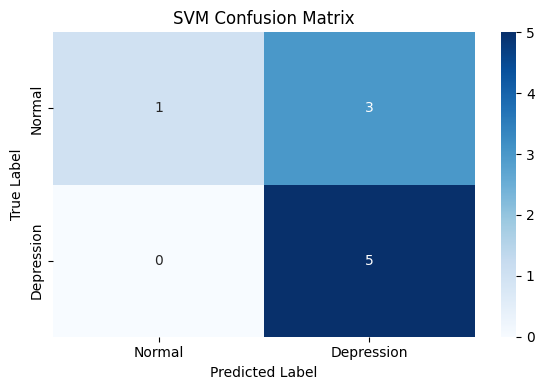

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Depression"], yticklabels=["Normal", "Depression"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Assuming X = features, y = labels (0 = normal, 1 = depression)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on the test set
rf_pred = rf_model.predict(X_test)

# Evaluate the model
print("----- Random Forest Results -----")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Classification Report:\n", classification_report(y_test, rf_pred))

# ✅ Use rf_pred here
cm = confusion_matrix(y_test, rf_pred)
print("Confusion Matrix:\n", cm)


----- Random Forest Results -----
Accuracy: 0.8888888888888888
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.83      1.00      0.91         5

    accuracy                           0.89         9
   macro avg       0.92      0.88      0.88         9
weighted avg       0.91      0.89      0.89         9

Confusion Matrix:
 [[3 1]
 [0 5]]


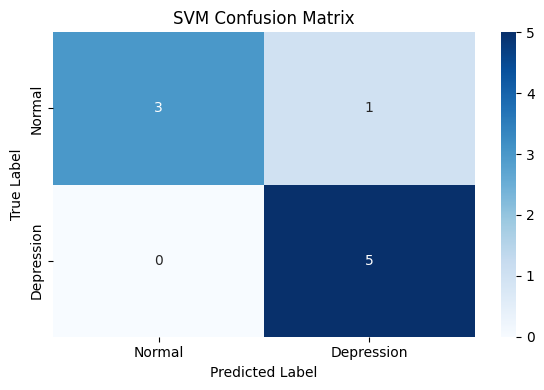

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion Matrix
cm = confusion_matrix(y_test, rf_pred)

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Depression"], yticklabels=["Normal", "Depression"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Create and train the KNN model
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)

# Predict on the test set
knn_pred = knn_model.predict(X_test)

# Evaluate the model
print("----- KNN Results -----")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Classification Report:\n", classification_report(y_test, knn_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, knn_pred)
print("Confusion Matrix:\n", cm)



----- KNN Results -----
Accuracy: 0.8461538461538461
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.67      0.80         6
           1       0.78      1.00      0.88         7

    accuracy                           0.85        13
   macro avg       0.89      0.83      0.84        13
weighted avg       0.88      0.85      0.84        13

Confusion Matrix:
 [[4 2]
 [0 7]]


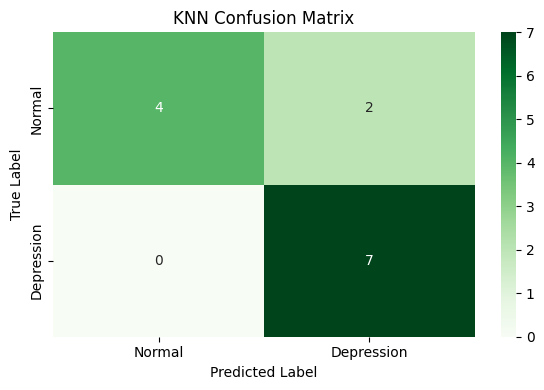

In [ ]:
# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=["Normal", "Depression"],
            yticklabels=["Normal", "Depression"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))


XGBoost Accuracy: 0.8461538461538461
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.67      0.80         6
           1       0.78      1.00      0.88         7

    accuracy                           0.85        13
   macro avg       0.89      0.83      0.84        13
weighted avg       0.88      0.85      0.84        13



e:\PYTHON\program\venv2\venv310\lib\site-packages\xgboost\training.py:183: UserWarning: [20:08:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create and train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict and evaluate
dt_pred = dt_model.predict(X_test)
print("----- Decision Tree Results -----")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Classification Report:\n", classification_report(y_test, dt_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, dt_pred))


----- Decision Tree Results -----
Accuracy: 0.6153846153846154
Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.50      0.55         6
           1       0.62      0.71      0.67         7

    accuracy                           0.62        13
   macro avg       0.61      0.61      0.61        13
weighted avg       0.61      0.62      0.61        13

Confusion Matrix:
 [[3 3]
 [2 5]]


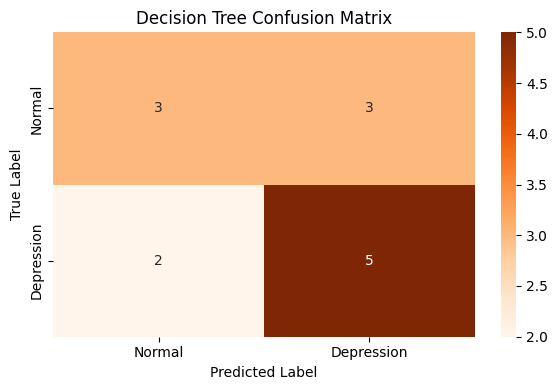

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, dt_pred)

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=["Normal", "Depression"],
            yticklabels=["Normal", "Depression"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()


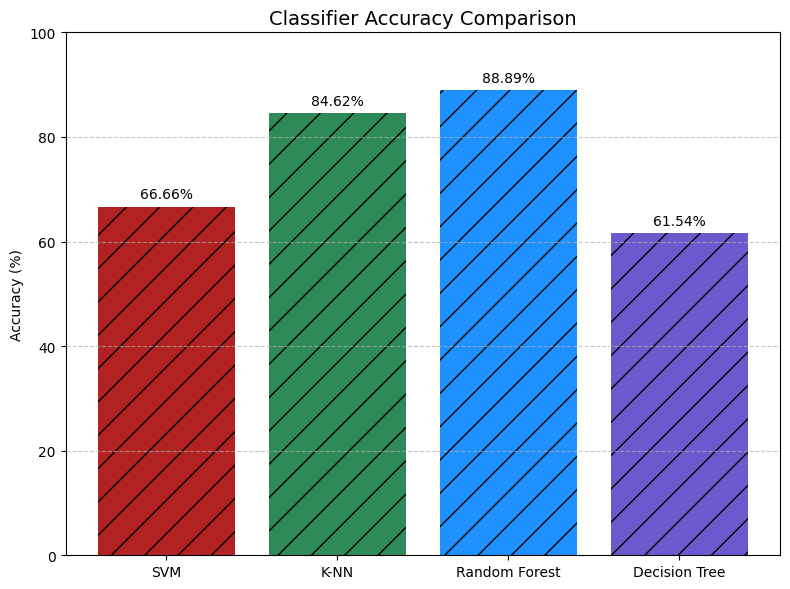

In [ ]:
import matplotlib.pyplot as plt

# Classifier names and their accuracies
classifiers = ['SVM', 'K-NN', 'Random Forest', 'Decision Tree']
accuracies = [66.66, 84.62, 88.89, 61.54]

# Create bar plot
colors = ['#b22222', '#2e8b57', '#1e90ff', '#6a5acd']  # Custom colors
hatch_style = '/'  # Diagonal hatch

plt.figure(figsize=(8, 6))
bars = plt.bar(classifiers, accuracies, color=colors, hatch=hatch_style)

# Add accuracy labels on top of each bar
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1,
             f'{acc:.2f}%', ha='center', va='bottom', fontsize=10)

# Title and labels
plt.title('Classifier Accuracy Comparison', fontsize=14)
plt.xlabel('')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

def plot_learning_curve(estimator, title, X, y, cv=5, n_jobs=None, train_sizes=np.linspace(0.1, 1.0, 5)):
    plt.figure(figsize=(6, 4))
    plt.title(title)
    plt.xlabel("Training examples")
    plt.ylabel("Score")
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes)
    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    plt.grid()
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


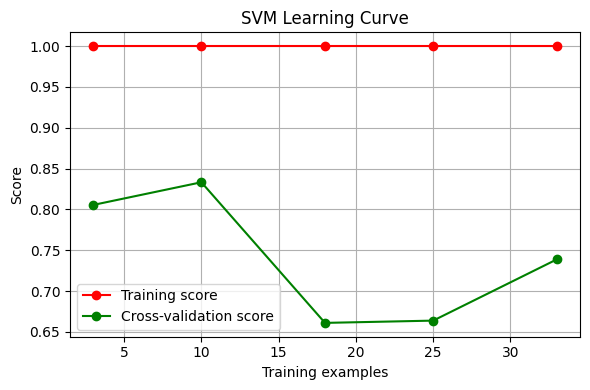

In [ ]:
plot_learning_curve(model, 'SVM Learning Curve', X, y, cv=5)


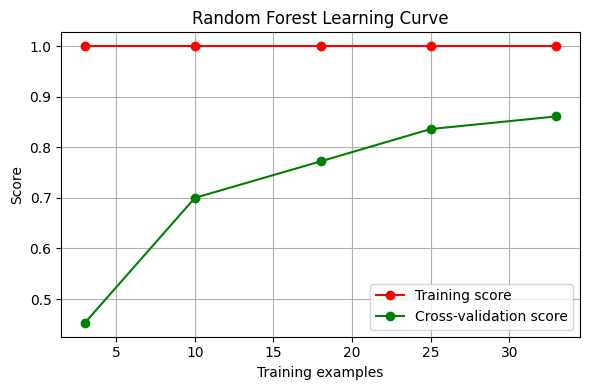

In [ ]:
plot_learning_curve(rf_model, 'Random Forest Learning Curve', X, y, cv=5)


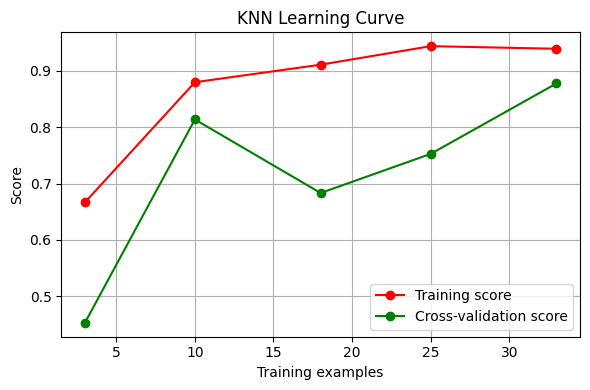

In [ ]:
plot_learning_curve(knn_model, 'KNN Learning Curve', X, y, cv=5)


e:\PYTHON\program\venv2\venv310\lib\site-packages\xgboost\training.py:183: UserWarning: [20:08:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
e:\PYTHON\program\venv2\venv310\lib\site-packages\xgboost\training.py:183: UserWarning: [20:08:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
e:\PYTHON\program\venv2\venv310\lib\site-packages\xgboost\training.py:183: UserWarning: [20:08:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
e:\PYTHON\program\venv2\venv310\lib\site-packages\xgboost\training.py:183: UserWarning: [20:08:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are

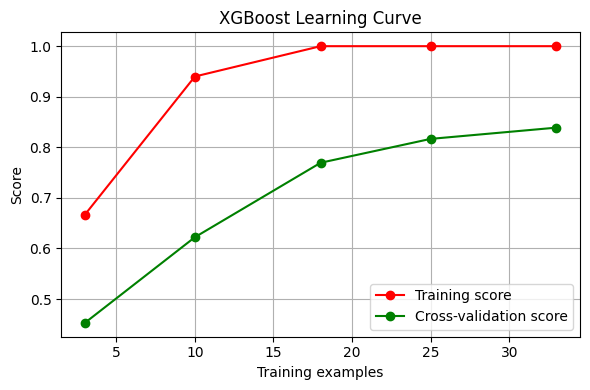

In [ ]:
plot_learning_curve(xgb, 'XGBoost Learning Curve', X, y, cv=5)


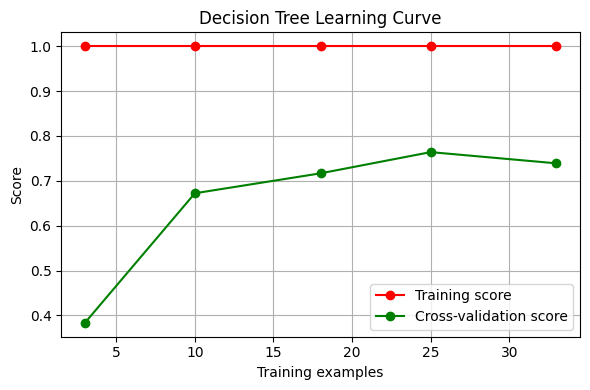

In [ ]:
plot_learning_curve(dt_model, 'Decision Tree Learning Curve', X, y, cv=5)
